In [37]:
%matplotlib inline

from IPython.display import Image

import qutip 
import qutip_qip.operations 
from qutip_qip.circuit import QubitCircuit, Gate, CircuitSimulator
from qutip import basis, tensor, qeye, sigmax
import random
import numpy as np


In [35]:
a=1
b=2
psi = (a*basis(2,0) + b*basis(2,1)).unit()
physical = [basis(2,0)]*4
state1 = tensor([psi]+physical)
state1

#np.set_printoptions(linewidth=200)
#print(state1.full().real.T)

Quantum object: dims=[[2, 2, 2, 2, 2], [1]], shape=(32, 1), type='ket', dtype=Dense
Qobj data =
[[0.4472136 ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.89442719]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]]

In [23]:
state1.ptrace(0).eigenstates()

(array([0., 1.]),
 array([Quantum object: dims=[[2], [1]], shape=(2, 1), type='ket', dtype=Dense
        Qobj data =
        [[-0.89442719]
         [ 0.4472136 ]]                                                       ,
        Quantum object: dims=[[2], [1]], shape=(2, 1), type='ket', dtype=Dense
        Qobj data =
        [[0.4472136 ]
         [0.89442719]]                                                        ],
       dtype=object))

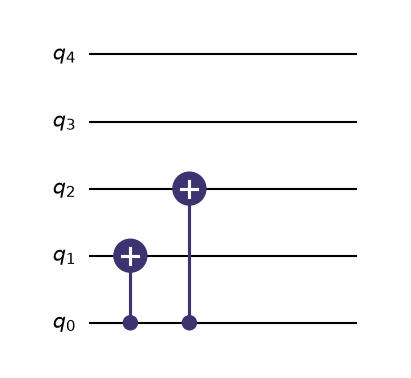

In [24]:
qenc = QubitCircuit(5, reverse_states=False)
qenc.add_gate("CNOT", controls=[0], targets=[1])
qenc.add_gate("CNOT", controls=[0], targets=[2])
qenc

In [26]:
encoded_state = qenc.run(state=state1)
encoded_state

Quantum object: dims=[[2, 2, 2, 2, 2], [1]], shape=(32, 1), type='ket', dtype=Dense
Qobj data =
[[0.4472136 ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.89442719]
 [0.        ]
 [0.        ]
 [0.        ]]

In [39]:
error_op = [qeye(2)]*5
flip_qubit = random.randint(0,2)
print("Bit-flipping qubit {}".format(flip_qubit))
error_op[flip_qubit] *= sigmax()

error0 = [qeye(2)]*5
error0[0] *= sigmax()

error1 = [qeye(2)]*5
error1[1] *= sigmax()

error2 = [qeye(2)]*5
error2[2] *= sigmax()

#APLICA EL ERROR QUE QUIERAS
errorstate=tensor(error_op) * encoded_state

Bit-flipping qubit 1


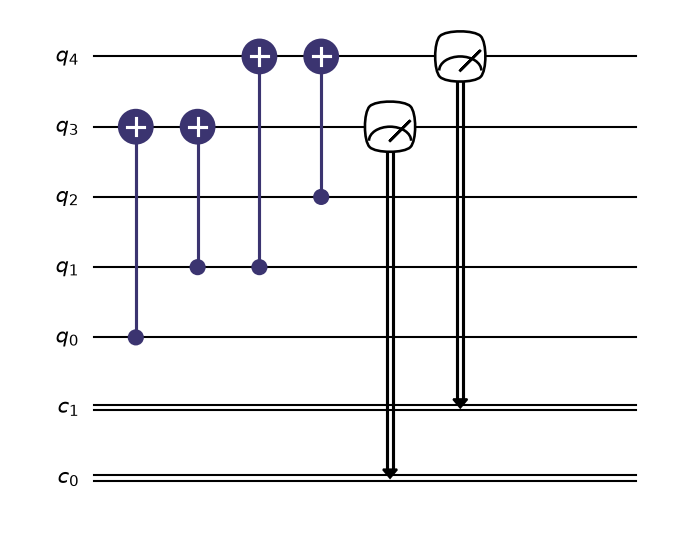

In [43]:
qdet1=QubitCircuit(5, reverse_states=False, num_cbits=2)
qdet1.add_gate("CNOT", controls=[0], targets=[3])
qdet1.add_gate("CNOT", controls=[1], targets=[3])

qdet1.add_gate("CNOT", controls=[1], targets=[4])
qdet1.add_gate("CNOT", controls=[2], targets=[4])


qdet1.add_measurement("M0", targets=[3], classical_store=0)
qdet1.add_measurement("M1", targets=[4], classical_store=1)

qdet1



In [47]:
sim_qdet1 = CircuitSimulator(qdet1)
resultado_noerror = sim_qdet1.run(state=encoded_state)
resultado_error = sim_qdet1.run(state=errorstate)

In [52]:
bits_clasicos_noerror = resultado_noerror.cbits
bits_clasicos_error = resultado_error.cbits
bits_clasicos_error

[[np.int64(1), np.int64(1)]]

In [53]:
estado_final_error = resultado_error.get_final_states()[0]
estado_final_noerror = resultado_noerror.get_final_states()[0]
estado_final_error

Quantum object: dims=[[2, 2, 2, 2, 2], [1]], shape=(32, 1), type='ket', dtype=Dense
Qobj data =
[[0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.4472136 ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.89442719]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]]

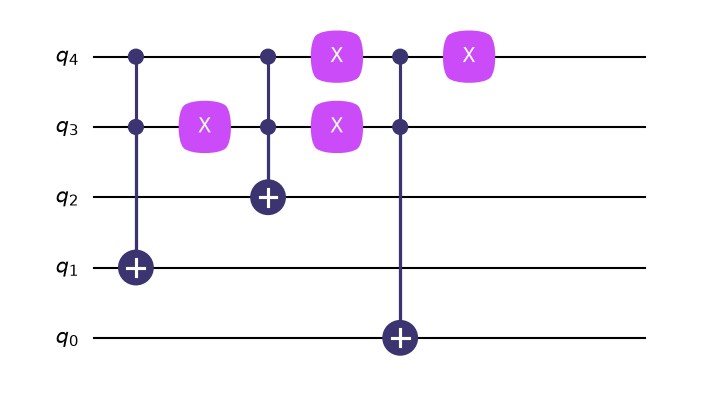

In [54]:
qcorr = QubitCircuit(5, reverse_states=False)
qcorr.add_gate("TOFFOLI", controls=[3,4], targets=[1])
qcorr.add_gate("X", targets=[3])
qcorr.add_gate("TOFFOLI", controls=[3,4], targets=[2])
qcorr.add_gate("X", targets=[3])
qcorr.add_gate("X", targets=[4])
qcorr.add_gate("TOFFOLI", controls=[3,4], targets=[0])
qcorr.add_gate("X", targets=[4])
qcorr



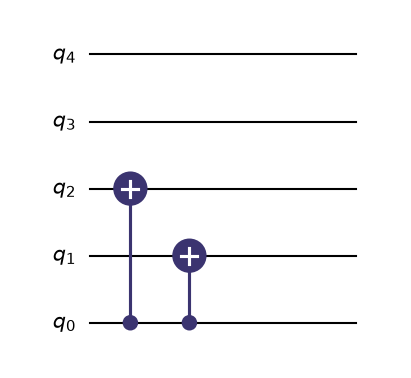

In [46]:
decod=QubitCircuit(5, reverse_states=False)
decod.add_gate("CNOT", controls=[0], targets=[2])
decod.add_gate("CNOT", controls=[0], targets=[1])
decod


In [55]:
decoded_state = qenc.run(state=errorstate)
decoded_state

Quantum object: dims=[[2, 2, 2, 2, 2], [1]], shape=(32, 1), type='ket', dtype=Dense
Qobj data =
[[0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.4472136 ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.89442719]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]]

In [56]:
decoded_state.ptrace(0).eigenstates()

(array([0.2, 0.8]),
 array([Quantum object: dims=[[2], [1]], shape=(2, 1), type='ket', dtype=Dense
        Qobj data =
        [[-1.]
         [ 0.]]                                                               , Quantum object: dims=[[2], [1]], shape=(2, 1), type='ket', dtype=Dense
                                                                                Qobj data =
                                                                                [[0.]
                                                                                 [1.]]                                                                ], dtype=object))